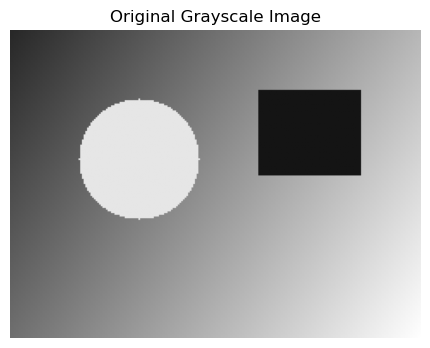

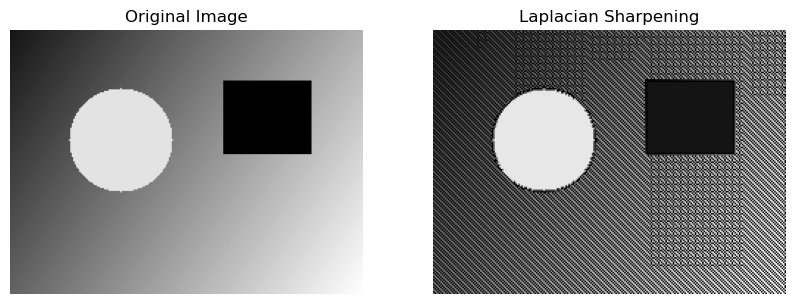

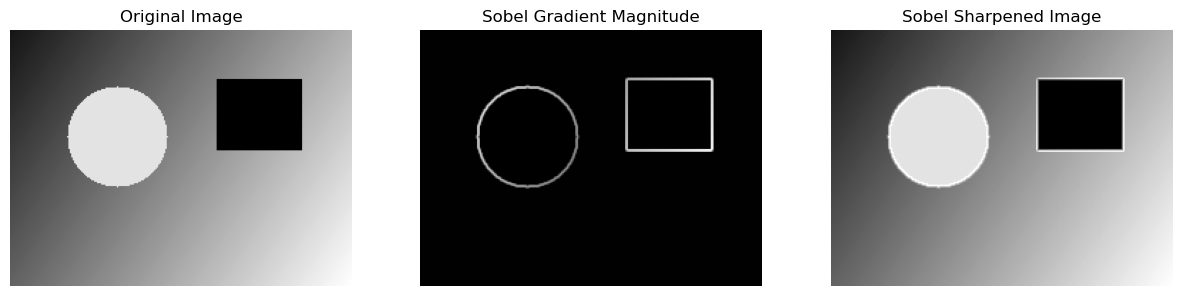

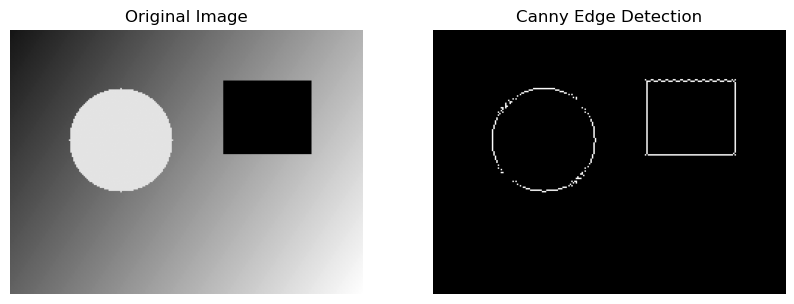

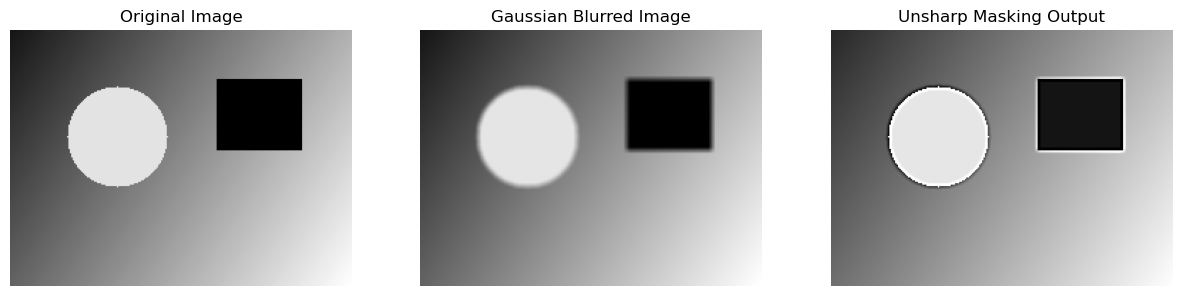

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate sample grayscale image
height, width = 180, 240
y, x = np.mgrid[0:height, 0:width]

gray_image = np.clip(40 + 0.6*x + 0.4*y, 0, 255).astype(np.uint8)

yy, xx = np.ogrid[:height, :width]
gray_image[(xx-75)**2 + (yy-75)**2 <= 35**2] = 230
gray_image[35:85, 145:205] = 20

# Display original image
plt.figure(figsize=(6, 4))
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()


# CASE 1: LAPLACIAN SHARPENING

padded = np.pad(gray_image, 1, mode='edge')

laplacian = (
    padded[:-2, 1:-1] +
    padded[2:, 1:-1] +
    padded[1:-1, :-2] +
    padded[1:-1, 2:] -
    4 * padded[1:-1, 1:-1]
)

laplacian_sharp = np.clip(
    gray_image.astype(float) - laplacian, 0, 255
).astype(np.uint8)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(laplacian_sharp, cmap='gray')
plt.title("Laplacian Sharpening")
plt.axis('off')
plt.show()


# CASE 2: SOBEL GRADIENT SHARPENING

sobel_x_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y_kernel = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])

padded = np.pad(gray_image.astype(float), 1, mode='edge')

gx = np.zeros_like(gray_image, dtype=float)
gy = np.zeros_like(gray_image, dtype=float)

for i in range(3):
    for j in range(3):
        region = padded[i:i+height, j:j+width]
        gx += region * sobel_x_kernel[i, j]
        gy += region * sobel_y_kernel[i, j]

gradient = np.sqrt(gx**2 + gy**2)

gradient = gradient / gradient.max() * 255

sobel_sharp = np.clip(
    gray_image.astype(float) + 0.5 * gradient,
    0, 255
).astype(np.uint8)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gradient, cmap='gray')
plt.title("Sobel Gradient Magnitude")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sobel_sharp, cmap='gray')
plt.title("Sobel Sharpened Image")
plt.axis('off')

plt.show()


# CASE 3: CANNY EDGE DETECTION

# Calculate gradient magnitude and direction
magnitude = np.sqrt(gx**2 + gy**2)

angle = np.rad2deg(np.arctan2(gy, gx))
angle = (angle + 180) % 180

# Non-maximum suppression
nms = np.zeros_like(magnitude)

for i in range(1, height-1):
    for j in range(1, width-1):
        direction = angle[i, j]
        value = magnitude[i, j]

        if (direction < 22.5 or direction >= 157.5):
            neighbors = [magnitude[i, j-1], magnitude[i, j+1]]
        elif direction < 67.5:
            neighbors = [magnitude[i-1, j+1], magnitude[i+1, j-1]]
        elif direction < 112.5:
            neighbors = [magnitude[i-1, j], magnitude[i+1, j]]
        else:
            neighbors = [magnitude[i-1, j-1], magnitude[i+1, j+1]]

        if value >= max(neighbors):
            nms[i, j] = value

# Double thresholding
low_threshold = 40
high_threshold = 100

strong = 255
weak = 75

edges = np.zeros_like(gray_image, dtype=np.uint8)

edges[nms >= high_threshold] = strong
edges[(nms >= low_threshold) & (nms < high_threshold)] = weak

# Hysteresis edge tracking
for i in range(1, height-1):
    for j in range(1, width-1):
        if edges[i, j] == weak:
            if np.any(edges[i-1:i+2, j-1:j+2] == strong):
                edges[i, j] = strong
            else:
                edges[i, j] = 0

edges[edges == weak] = 0

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis('off')

plt.show()


# CASE 4: UNSHARP MASKING
# Gaussian filter size = 5x5, sigma = 3

def gaussian_kernel(size, sigma):
    ax = np.arange(-(size//2), size//2 + 1)
    xx, yy = np.meshgrid(ax, ax)

    kernel = np.exp(
        -(xx**2 + yy**2) / (2*sigma**2)
    )

    return kernel / kernel.sum()


kernel = gaussian_kernel(5, 3)

padded = np.pad(gray_image.astype(float), 2, mode='edge')

blurred = np.zeros_like(gray_image, dtype=float)

for i in range(5):
    for j in range(5):
        region = padded[i:i+height, j:j+width]
        blurred += region * kernel[i, j]

mask = gray_image.astype(float) - blurred

unsharp_amount = 1.5

unsharp_image = np.clip(
    gray_image.astype(float) + unsharp_amount * mask,
    0, 255
).astype(np.uint8)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap='gray')
plt.title("Gaussian Blurred Image")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(unsharp_image, cmap='gray')
plt.title("Unsharp Masking Output")
plt.axis('off')

plt.show()